# Describing the Structure of Water

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4v2/blob/main/temp/01-structure.ipynb)
:::


In [ ]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import rdkit
except ImportError:
    !pip -q install rdkit
    import rdkit

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB:
    if not Path("styles/tufte.mplstyle").exists():
        !wget -q -N -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
        !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py
    plt.style.use("styles/tufte.mplstyle")
    nproc = 2          # Colab gives you 2 cores
else:
    sys.path.insert(0, "..")                    # psi4_helpers.py is one folder up
    plt.style.use("../styles/tufte.mplstyle")
    nproc = 4          # house limit: 4 threads

import psi4_helpers as ph

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = False

# All Psi4 .out and .log files go into the output folder
output_dir = Path("output")
output_dir.mkdir(exist_ok=True)

# Resources: house limits are 4 threads and 4 GB
psi4.set_num_threads(nproc)
psi4.set_memory("2 GB")


  Threads set to 4 by Python driver.

  Memory set to   1.863 GiB by Python driver.


Before *Psi4* can calculate anything, we have to tell it **where the atoms are**. In this notebook we describe water in four different ways and check that *Psi4* understands each one as the same molecule.

## What You Will Learn
- How to write a molecule as **Cartesian coordinates** ($xyz$).
- How to write a molecule as **internal coordinates** (a *Z-matrix*) using bond lengths and angles.
- How *Psi4* detects **symmetry** and moves the molecule into a standard orientation.
- How to get a starting structure from a **SMILES string** with *RDKit*.
- How to run a first **single-point energy** and where the output files go.

```{note} Settings used in every notebook
:class: dropdown
The setup cell at the top of each notebook sets the resources that *Psi4* may use:

`psi4.set_num_threads(nproc)`
: The number of CPU cores. The house limit is 4 threads. *Colab* gives you 2. Water is so small that extra cores barely help; they matter for larger molecules.

`psi4.set_memory("2 GB")`
: The memory *Psi4* may use for its arrays. The house limit is 4 GB. Water needs far less, but 2 GB is a safe value that also works on *Colab* (about 12 GB total). Alternative: `"500 MB"` is plenty for most of these calculations; larger values only matter for big basis sets or coupled-cluster methods on bigger molecules.

`psi4.set_output_file("output/name.out", False)`
: Where *Psi4* writes its detailed text output. *Psi4* also writes a `.log` file with the same name beside it. `False` means overwrite the file each time; `True` would append. We keep every output in the `output` folder so the notebook folder stays tidy. A file called `timer.dat` may still appear beside the notebook; you can ignore it.
```

In [2]:
psi4.set_output_file("output/01-structure.out", False);

## 1. Cartesian Coordinates

The most direct description lists each atom with its $x$, $y$ and $z$ position. The first line is the **charge** and **spin multiplicity** (here `0 1`: neutral, all electrons paired, a *singlet*). Coordinates are in ångströms unless we say otherwise.

These coordinates were written by hand from the experimental structure ($r_{\mathrm{OH}} = 0.958$ Å, $\angle\mathrm{HOH} = 104.5°$).

In [3]:
water_xyz = psi4.geometry("""
0 1
O    0.000000    0.000000    0.000000
H    0.757900    0.586700    0.000000
H   -0.757900    0.586700    0.000000
""")

water_xyz.update_geometry()      # make Psi4 process the input now
print("Point group:", water_xyz.schoenflies_symbol())
print(water_xyz.save_string_xyz_file())

Point group: c2v
3

 O    0.000000000000    0.000000000000   -0.065660456158
 H    0.757900000000    0.000000000000    0.521039543842
 H   -0.757900000000   -0.000000000000    0.521039543842



Look carefully: the coordinates printed by *Psi4* are **not** the ones we typed. *Psi4* has

1. moved the **centre of mass** to the origin, and
2. **rotated** the molecule so its symmetry elements line up with the axes.

It has also found that water belongs to the $C_{2v}$ **point group**. *Psi4* uses that symmetry to label orbitals and vibrations and to speed up some calculations.

```{note} When to stop Psi4 from moving the molecule
:class: dropdown
Add `no_com` and `no_reorient` lines inside the geometry string to keep your coordinates exactly as typed. This is useful when you want to compare structures in the same frame, or when an external field or solvent cavity must stay fixed. Add `symmetry c1` to switch off symmetry entirely. Some methods and add-ons (for example the PCM solvent model, used later) require `symmetry c1`.
```

In [4]:
water_fixed = psi4.geometry("""
0 1
O    0.000000    0.000000    0.000000
H    0.757900    0.586700    0.000000
H   -0.757900    0.586700    0.000000
no_com
no_reorient
symmetry c1
""")
water_fixed.update_geometry()
print("Point group:", water_fixed.schoenflies_symbol())
print(water_fixed.save_string_xyz_file())

Point group: c1
3

 O    0.000000000000    0.000000000000    0.000000000000
 H    0.757900000000    0.586700000000    0.000000000000
 H   -0.757900000000    0.586700000000    0.000000000000



## 2. Internal Coordinates (*Z-matrix*)

A *Z-matrix* builds the molecule one atom at a time from **bond lengths** and **angles** (and, for four or more atoms, **dihedral angles**).

```text
O                  ← atom 1 sits at the origin
H 1 0.958          ← atom 2 is 0.958 Å from atom 1
H 1 0.958 2 104.5  ← atom 3 is 0.958 Å from atom 1, with angle 3-1-2 = 104.5°
```

We can also use **variables** for the values. This makes it easy to change one parameter, which we will do later when we scan the bond angle and stretch a bond.

In [5]:
water_zmat = psi4.geometry("""
0 1
O
H 1 r
H 1 r 2 a

r = 0.958
a = 104.5
""")
water_zmat.update_geometry()
print("Point group:", water_zmat.schoenflies_symbol())
print(water_zmat.save_string_xyz_file())

Point group: c2v
3

 O    0.000000000000    0.000000000000   -0.065638538108
 H    0.000000000000   -0.757480611647    0.520865616165
 H    0.000000000000    0.757480611647    0.520865616165



## 3. Measuring the Structure

The helper functions in `psi4_helpers.py` measure distances and angles. Atoms are numbered from **0** in *Python*, so oxygen is atom 0 and the hydrogens are atoms 1 and 2.

In [6]:
for name, mol in [("Cartesian", water_xyz), ("Z-matrix", water_zmat)]:
    r = ph.bond_length(mol, 0, 1)
    a = ph.bond_angle(mol, 1, 0, 2)
    print(f"{name:10s}  r(O-H) = {r:.4f} Å   angle(H-O-H) = {a:.2f}°")

Cartesian   r(O-H) = 0.9585 Å   angle(H-O-H) = 104.51°
Z-matrix    r(O-H) = 0.9580 Å   angle(H-O-H) = 104.50°


Here is the Z-matrix structure as a ball-and-stick model.

```{tip} Fixed pictures or 3D models you can rotate
The notebooks draw molecules, orbitals and surfaces as fixed pictures, as they appear in this book. Set `INTERACTIVE = True` in the first cell and rerun the notebook to get 3D models that you can rotate and zoom with the mouse.
```

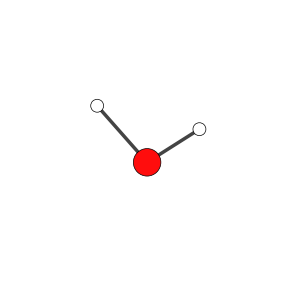

In [7]:
ph.show_molecule(water_zmat, interactive=INTERACTIVE)

## 4. A Starting Structure from *RDKit*

For bigger molecules, typing coordinates is slow and error-prone. *RDKit* can build a reasonable 3D structure from a **SMILES** string using a force field (MMFF). This is only a **starting guess**; we will improve it with *Psi4* in the next notebook.

In [8]:
from rdkit import Chem
from rdkit.Chem import AllChem

rdmol = Chem.AddHs(Chem.MolFromSmiles("O"))     # SMILES for water is just "O"
AllChem.EmbedMolecule(rdmol, randomSeed=42)      # randomSeed makes the result repeatable
AllChem.MMFFOptimizeMolecule(rdmol)              # quick force-field clean-up

xyz_lines = Chem.MolToXYZBlock(rdmol).splitlines()[2:]    # drop the atom count and comment lines
charge = Chem.GetFormalCharge(rdmol)
water_rdkit = psi4.geometry(f"{charge} 1\n" + "\n".join(xyz_lines))
water_rdkit.update_geometry()

print(f"r(O-H) = {ph.bond_length(water_rdkit, 0, 1):.4f} Å   angle = {ph.bond_angle(water_rdkit, 1, 0, 2):.2f}°")

r(O-H) = 0.9690 Å   angle = 103.98°


```{note} Other ways to get a starting structure
:class: dropdown
- **PubChem:** `psi4.geometry("pubchem:water")` downloads a structure by name. It needs an internet connection and sometimes fails when PubChem is busy, so it is less reliable in a class setting.
- **Draw it:** programs such as *Avogadro* or *IQmol* let you draw a molecule and export an `.xyz` file.
- **From a file:** read an `.xyz` file with *Python* and pass the text to `psi4.geometry()` (remember to add the charge/multiplicity line).
```

## 5. A First Energy

Now we ask *Psi4* for the **energy** of each version of water using Hartree–Fock theory and the cc-pVDZ basis set. Because the Cartesian, *Z-matrix* and *RDKit* structures are almost identical, the energies should be almost identical too.

```{note} Psi4 settings in this cell
:class: dropdown
`"hf/cc-pvdz"`
: The **method** (Hartree–Fock, HF) and **basis set** (cc-pVDZ) written together. HF is the cheapest *ab initio* method and is the house default for first calculations. cc-pVDZ is a small but well-designed basis set.
: *Alternatives:* `"hf/6-31g*"` (a Pople basis set that is common in textbooks), `"b3lyp/6-31g*"` (a DFT method, usually more accurate for the same cost), `"mp2/cc-pvdz"` (adds electron correlation). We compare these in the *Level of Effort* notebook.

`scf_type: "pk"`
: How *Psi4* handles the two-electron integrals. `"pk"` computes them exactly. *Psi4*'s usual default is density fitting (`"df"`), which approximates them and is much faster for big molecules. For water the difference is about $10^{-5}$ hartree and both take well under a second. We use `"pk"` here so you can compare numbers with other programs.

`molecule=`
: Tells `psi4.energy()` which molecule to use. Without it, *Psi4* uses the **most recently defined** molecule, which is a common source of mistakes when a notebook defines several.
```

In [9]:
psi4.set_options({"basis": "cc-pvdz", "scf_type": "pk"})

results = []
for name, mol in [("Cartesian", water_xyz), ("Z-matrix", water_zmat), ("RDKit", water_rdkit)]:
    E = psi4.energy("hf", molecule=mol)
    results.append({"structure": name, "energy (hartree)": E})

df = pd.DataFrame(results)
df["relative (kJ/mol)"] = (df["energy (hartree)"] - df["energy (hartree)"].min()) * psi4.constants.hartree2kJmol
df

,structure,energy (hartree),relative (kJ/mol)
0,Cartesian,-76.026738,0.060322
1,Z-matrix,-76.026761,0.000000
2,RDKit,-76.025988,2.027800


The energies are about $-76.02$ hartree. On its own this number means very little: it is the energy needed to pull every electron and nucleus apart to infinity. What matters in chemistry are **energy differences** calculated at the **same level of theory**. Here the hand-typed structures agree to within 0.1 kJ/mol, while the *RDKit* structure is about 2 kJ/mol higher because its force-field bond length (0.969 Å) and angle are slightly different.

```{tip} Look at the output file
Open `output/01-structure.out`. Search for `@DF-RHF Final Energy` or `@RHF Final Energy` to find the energy, and look at the list of **orbital energies** labelled with $C_{2v}$ symmetry labels (`a1`, `b1`, `b2`). The helper function `ph.search_file()` can do the searching for you.
```

In [10]:
ph.search_file("output/01-structure.out", "Final Energy")

   213:   @RHF Final Energy:   -76.02673775845162
   418:   @RHF Final Energy:   -76.02676073371377
   621:   @RHF Final Energy:   -76.02598838562820


## Summary
- *Psi4* accepts Cartesian coordinates or a *Z-matrix*; both give the same molecule.
- *Psi4* moves and rotates the molecule and detects its point group unless told not to.
- A SMILES string and *RDKit* give quick starting structures.
- Absolute energies are not meaningful on their own; compare **differences** at the same level of theory.